In [9]:
library(tidyverse)
library(emmeans)
library(sjPlot)


In [2]:
descriptions <- read_csv(
    "spatial_descriptions.csv"
)

reference <- read_csv(
    "reference.csv"
)

df_descriptions <- descriptions %>%
    mutate(corpus = "descriptions")%>%
    mutate(corpus = as.factor(corpus))

df_reference <- reference %>%
    mutate(corpus = "reference")%>%
    mutate(corpus = as.factor(corpus))

df <- bind_rows(df_descriptions, df_reference)
head(df)

Rows: 9601 Columns: 17
-- Column specification --------------------------------------------------------
Delimiter: ","
chr  (3): sentence_id, sentence, lemmatized_sentence
dbl (14): length, imagability_mean, coverage_glasgow, visual_mean, auditory_...

i Use `spec()` to retrieve the full column specification for this data.
i Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 409979 Columns: 14
-- Column specification --------------------------------------------------------
Delimiter: ","
chr  (3): sentence_id, sentence, lemmatized_sentence
dbl (11): length, ANNOTATION, imagability_mean, coverage_glasgow, visual_mea...

i Use `spec()` to retrieve the full column specification for this data.
i Specify the column types or set `show_col_types = FALSE` to quiet this message.


sentence_id,sentence,length,lemmatized_sentence,imagability_mean,coverage_glasgow,visual_mean,auditory_mean,olfactory_mean,haptic_mean,coverage_lancaster,olfactory_mean_z,auditory_mean_z,haptic_mean_z,visual_mean_z,Book_ID,pub_year,corpus,ANNOTATION
<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<dbl>
gutenberg-30627-3170,The great hoarse whistles roared and the shrill siren whistles screamed and the car bells clanged and the church bells rang.,23,"['great', 'hoarse', 'whistle', 'roar', 'shrill', 'siren', 'whistle', 'scream', 'car', 'bell', 'clang', 'church', 'bell', 'ring']",5.580182,0.7857143,2.313147,3.901054,0.2813759,1.0837552,1.0000000,-0.88367989,5.859675,-1.1208810,-2.955713,30627,1918,descriptions,NA
gutenberg-835-167,"Once again the air was full of wonderful sound, voices and song, and the cry of the bells; but within all was silence.",28,"['air', 'wonderful', 'sound', 'voice', 'song', 'cry', 'bell', 'silence']",4.412714,0.8750000,1.629432,3.826526,0.5846099,1.0152407,1.0000000,0.07903425,5.696251,-1.2683595,-4.625681,835,1911,descriptions,NA
gutenberg-41711-2938,"The music played, the fountain<U+2019>s tinkle mingled with the hum of many voices, the footfalls, the clinking of glass and china.",27,"['music', 'play', 'fountain', 'tinkle', 'mingle', 'hum', 'voice', 'footfall', 'clinking', 'glass', 'china']",4.935600,0.4545455,2.442304,3.643140,0.3392569,0.8407814,0.8181818,-0.69991798,5.294124,-1.6438857,-2.640247,41711,1903,descriptions,NA
gutenberg-15432-2123,"Something like laughter, or, as it were, the clapper of a scarer of birds, echoed among the rocks at the rattling of the rowlocks.",30,"['like', 'laughter', 'clapper', 'scarer', 'bird', 'echo', 'rock', 'rattling', 'rowlock']",5.374000,0.4444444,2.571735,3.594337,0.4789634,1.3100905,0.7777778,-0.25637464,5.187108,-0.6336907,-2.324113,15432,1904,descriptions,NA
gutenberg-47702-1413,"There was a clatter of china-ware, deep, boisterous laughter, and a woman's voice in shrill accents.",24,"['clatter', 'china', 'ware', 'deep', 'boisterous', 'laughter', 'woman', 'voice', 'shrill', 'accent']",4.485667,0.6000000,2.329998,3.566714,0.5429438,1.0465090,0.8000000,-0.05324832,5.126537,-1.2010541,-2.914555,47702,1903,descriptions,NA
gutenberg-23299-439,"It was pouring now, and there was wind with the rain, since otherwise it could not have made such a noise against the glass.",28,"['pour', 'wind', 'rain', 'noise', 'glass']",5.125667,0.6000000,2.453499,3.541193,0.8611693,2.4692733,0.8000000,0.95706117,5.070575,1.8614680,-2.612905,23299,1909,descriptions,NA


In [3]:
df_long_descriptions <- descriptions %>%
    pivot_longer(cols = c("olfactory_mean", "auditory_mean", "haptic_mean", "visual_mean", "imagability_mean"),
                 names_to = "dimension",
                 values_to = "value")

df_long_descriptions <- df_long_descriptions %>%
    mutate(dimension = as.factor(dimension))


df_long_reference <- reference %>%
    pivot_longer(cols = c("olfactory_mean", "auditory_mean", "haptic_mean", "visual_mean", "imagability_mean"),
                 names_to = "dimension",
                 values_to = "value")

df_long_reference <- df_long_reference %>%
    mutate(dimension = as.factor(dimension))


df_long_descriptions <- df_long_descriptions %>%
    mutate(corpus = "descriptions")%>%
    mutate(corpus = as.factor(corpus))

df_long_reference <- df_long_reference %>%
    mutate(corpus = "reference")%>%
    mutate(corpus = as.factor(corpus))


df_concat <- bind_rows(df_long_descriptions, df_long_reference) %>%
     dplyr::select(sentence_id, dimension, value, corpus, pub_year)

### Strength of Sensory Modalities and Imageability

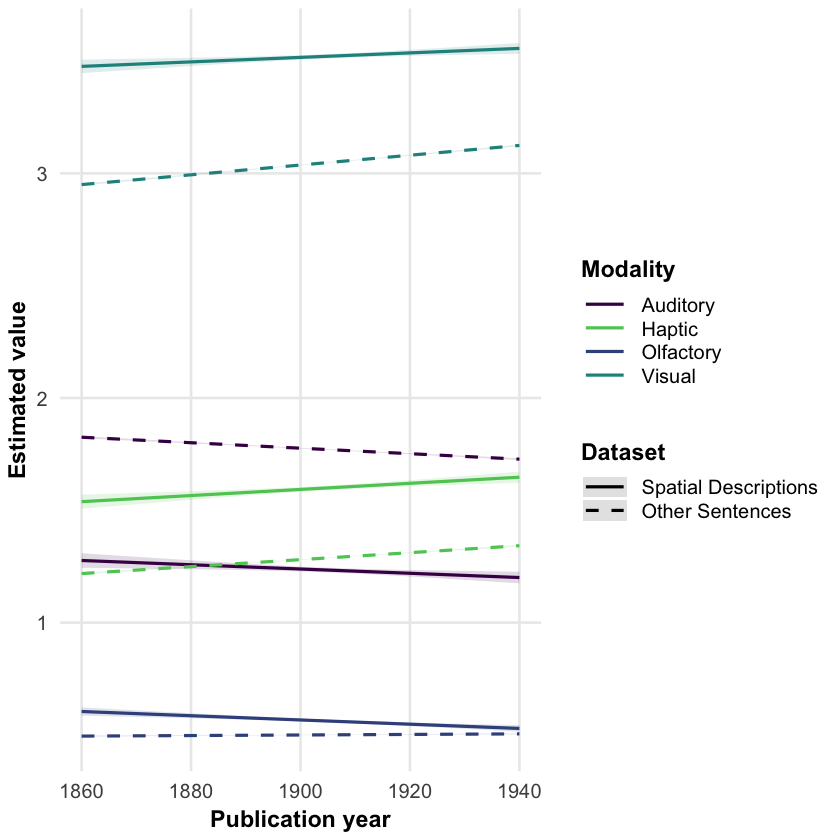

In [4]:
# Lancaster Sensorimotor Norms

dimension_colors <- c(
  "auditory_mean" = "#440154",
  "olfactory_mean"  = "#3b528b",
  "haptic_mean"    = "#5ec962",
  "visual_mean"    = "#21918c"
)

dimensions <- names(dimension_colors)

all_data <- list()


for (dimension in dimensions) {

  model <- glm(
    value ~ pub_year * corpus,
    data = df_concat %>%
      filter(dimension == !!dimension),
    family = gaussian
  )

  # print(paste("Summary for dimension:", dimension))
  # print(summary(model))

  p <- plot_model(
    model,
    type = "emm",
    terms = c("pub_year", "corpus"),
    title = "",
    colors = c("#1B9E77", "#D95F02"),
    dodge = 0.5,
    dot.size = 0
  )

  dat <- as.data.frame(p$data)
  dat$dimension <- dimension
  all_data[[dimension]] <- dat
}


# combine all modalities
dat_all <- do.call(rbind, all_data)
dat_all <- as.data.frame(dat_all)
dat_all$corpus_type <- as.character(dat_all$group)
dat_all$corpus_type <- factor(
  dat_all$corpus_type,
  levels = c("descriptions", "reference")
)


p <- ggplot(
  dat_all,
  aes(
    x = x,
    y = predicted,

    # dimension
    color = dimension,

    # corpus
    linetype = corpus_type,

    group = interaction(dimension, corpus_type)
  )
) +



# confidence intervals
  geom_ribbon(
    aes(
      ymin = conf.low,
      ymax = conf.high,
      fill = dimension
    ),
    alpha = 0.15,
    color = NA
  ) +

# lines
  geom_line(
    linewidth = 0.9
  ) +

# dimension colors
  scale_color_manual(
    values = dimension_colors,
    name = "Modality",
    labels = c(
      "olfactory_mean" = "Olfactory",
      "auditory_mean"  = "Auditory",
      "visual_mean"    = "Visual",
      "haptic_mean"    = "Haptic"
    )
  ) +

  scale_fill_manual(
    values = dimension_colors,
    guide = "none"
  ) +


# corpus linetypes
  scale_linetype_manual(
    values = c(
      "descriptions" = "solid",
      "reference" = "dashed"
    ),
    labels = c(
      "descriptions" = "Spatial Descriptions",
      "reference" = "Other Sentences"
    ),
    name = "Dataset"
  ) +


  labs(
    x = "Publication year",
    y = "Estimated value"
  ) +

  theme_minimal(base_size = 16) +

  theme(
    legend.position = "right",
    legend.direction = "vertical",

    legend.text = element_text(size = 12),
    legend.title = element_text(size = 14, face = "bold"),

    axis.text = element_text(size = 12),
    axis.title = element_text(size = 14, face = "bold"),

    panel.grid.minor = element_blank(),

    plot.margin = margin(5, 5, 5, 5),

    legend.key.height = unit(0.5, "cm"),
    legend.key.width = unit(1, "cm"),

    legend.justification = c(0, 0.5)
  )


ggsave(
  "temporal_trends_complete.png",
  plot = p,
  width = 8,
  height = 4,
  units = "in",
  dpi = 300
)

p


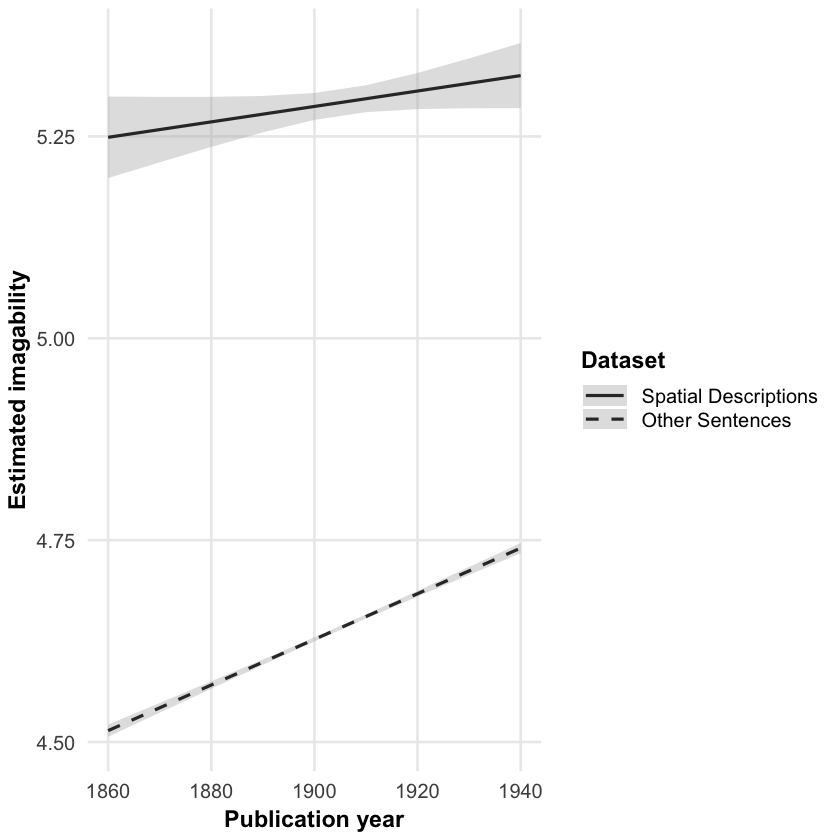

In [5]:
# Imageability

model <- glm(
  value ~ pub_year * corpus,
  data = df_concat %>%
    filter(dimension == "imagability_mean"),
  family = gaussian
)

p_emm <- plot_model(
  model,
  type = "emm",
  terms = c("pub_year", "corpus"),
  title = "",
  colors = c("grey30", "grey30"),
  dodge = 0.5,
  dot.size = 0
)

dat <- as.data.frame(p_emm$data)


dat$corpus_type <- as.character(dat$group)

dat$corpus_type <- factor(
  dat$corpus_type,
  levels = c("descriptions", "reference")
)

p <- ggplot(
  dat,
  aes(
    x = x,
    y = predicted,

    linetype = corpus_type,

    group = corpus_type
  )
) +


  geom_ribbon(
    aes(
      ymin = conf.low,
      ymax = conf.high
    ),
    fill = "grey70",
    alpha = 0.4,
    color = NA
  ) +


  geom_line(
    color = "grey20",
    linewidth = 0.9
  ) +

  scale_linetype_manual(
    values = c(
      "descriptions" = "solid",
      "reference" = "dashed"
    ),
    labels = c(
      "descriptions" = "Spatial Descriptions",
      "reference" = "Other Sentences"
    ),
    name = "Dataset"
  ) +

  labs(
    x = "Publication year",
    y = "Estimated imagability"
  ) +

  theme_minimal(base_size = 16) +

  theme(
    legend.position = "right",
    legend.direction = "vertical",

    legend.text = element_text(size = 12),
    legend.title = element_text(size = 14, face = "bold"),

    axis.text = element_text(size = 12),
    axis.title = element_text(size = 14, face = "bold"),

    panel.grid.minor = element_blank(),

    plot.margin = margin(5, 5, 5, 5),

    legend.key.height = unit(0.5, "cm"),
    legend.key.width = unit(1, "cm"),

    legend.justification = c(0, 0.5)
  )

ggsave(
  "temporal_trends_imagability.png",
  plot = p,
  width = 8,
  height = 4,
  units = "in",
  dpi = 300
)

p

In [6]:
# model output

dimensions <- c(
  "olfactory_mean",
  "auditory_mean",
  "visual_mean",
  "haptic_mean",
  "imagability_mean"
)

mean_year <- mean(
  df_concat$pub_year,
  na.rm = TRUE
)

min_year <- min(
  df_concat$pub_year,
  na.rm = TRUE
)

max_year <- max(
  df_concat$pub_year,
  na.rm = TRUE
)


for (dim_name in dimensions) {

  cat("\n=====================================\n")
  cat("Dimension:", dim_name, "\n")
  cat("=====================================\n")


  dat <- df_concat %>%
    dplyr::filter(dimension == dim_name) %>%
    dplyr::filter(
      complete.cases(value, pub_year, corpus)
    ) %>%
    dplyr::mutate(
      pub_year_c = pub_year - mean_year
    )

  model <- glm(
    value ~ pub_year_c * corpus,
    data = dat,
    family = gaussian
  )


  print(coef(summary(model)))


  # temporal trends within each corpus
  trends <- emtrends(
    model,
    ~ corpus,
    var = "pub_year_c"
  )

  trend_results <- summary(
    trends,
    infer = c(TRUE, TRUE)
  )

  # difference in temporal trends between corpora
  trend_difference <- summary(
    pairs(trends),
    infer = c(TRUE, TRUE)
  )


# corpus differences in mean publication year
  corpus_means <- emmeans(
    model,
    ~ corpus,
    at = list(pub_year_c = 0)
  )

  corpus_difference_mean <- summary(
    pairs(corpus_means),
    infer = c(TRUE, TRUE)
  )


# corpus differences in first publication year
  corpus_first_year <- emmeans(
    model,
    ~ corpus,
    at = list(
      pub_year_c = min_year - mean_year
    )
  )

  corpus_difference_first <- summary(
    pairs(corpus_first_year),
    infer = c(TRUE, TRUE)
  )


# corpus differences in last publication year
  corpus_last_year <- emmeans(
    model,
    ~ corpus,
    at = list(
      pub_year_c = max_year - mean_year
    )
  )

  corpus_difference_last <- summary(
    pairs(corpus_last_year),
    infer = c(TRUE, TRUE)
  )


  results_table <- bind_rows(

    # temporal trends within each corpus
    trend_results %>%
      mutate(
        effect = "Publication year",
        contrast = paste("within", corpus)
      ) %>%
      transmute(
        Predictor = paste(effect, "-", contrast),
        Effect = round(pub_year_c.trend, 3),
        CI = paste0(
          "[", round(lower.CL, 3),
          ", ", round(upper.CL, 3), "]"
        ),
        p = format.pval(
          p.value,
          digits = 3,
          eps = .001
        )
      ),

    # difference in temporal trends between corpora
    trend_difference %>%
      transmute(
        Predictor = "Publication year × Corpus",
        Effect = round(estimate, 3),
        CI = paste0(
          "[", round(lower.CL, 3),
          ", ", round(upper.CL, 3), "]"
        ),
        p = format.pval(
          p.value,
          digits = 3,
          eps = .001
        )
      ),

    # corpus differences in mean publication year
    corpus_difference_mean %>%
      transmute(
        Predictor = paste0(
          "Corpus difference at mean publication year (",
          round(mean_year, 1),
          ")"
        ),
        Effect = round(estimate, 3),
        CI = paste0(
          "[", round(lower.CL, 3),
          ", ", round(upper.CL, 3), "]"
        ),
        p = format.pval(
          p.value,
          digits = 3,
          eps = .001
        )
      ),

    # corpus differences in first publication year
    corpus_difference_first %>%
      transmute(
        Predictor = paste0(
          "Corpus difference at first publication year (",
          min_year,
          ")"
        ),
        Effect = round(estimate, 3),
        CI = paste0(
          "[", round(lower.CL, 3),
          ", ", round(upper.CL, 3), "]"
        ),
        p = format.pval(
          p.value,
          digits = 3,
          eps = .001
        )
      ),

    # corpus differences in last publication year
    corpus_difference_last %>%
      transmute(
        Predictor = paste0(
          "Corpus difference at last publication year (",
          max_year,
          ")"
        ),
        Effect = round(estimate, 3),
        CI = paste0(
          "[", round(lower.CL, 3),
          ", ", round(upper.CL, 3), "]"
        ),
        p = format.pval(
          p.value,
          digits = 3,
          eps = .001
        )
      )
  )

  print(results_table)

  cat("\nFirst publication year:", min_year, "\n")
  cat("Mean publication year:", round(mean_year, 2), "\n")
  cat("Last publication year:", max_year, "\n")

  cat("\n")
}



Dimension: olfactory_mean 
                                Estimate   Std. Error    t value      Pr(>|t|)
(Intercept)                 0.5628429299 0.0029144356 193.122447  0.000000e+00
pub_year_c                 -0.0009427125 0.0001956093  -4.819365  1.440662e-06
corpusreference            -0.0626946122 0.0029481708 -21.265597 2.672252e-100
pub_year_c:corpusreference  0.0010665732 0.0001978734   5.390180  7.042478e-08


NOTE: Results may be misleading due to involvement in interactions

NOTE: Results may be misleading due to involvement in interactions

NOTE: Results may be misleading due to involvement in interactions



                                           Predictor Effect               CI
1             Publication year - within descriptions -0.001 [-0.001, -0.001]
2                Publication year - within reference  0.000           [0, 0]
3                   Publication year <U+00D7> Corpus -0.001 [-0.001, -0.001]
4  Corpus difference at mean publication year (1904)  0.063   [0.057, 0.068]
5 Corpus difference at first publication year (1862)  0.107    [0.09, 0.125]
6  Corpus difference at last publication year (1939)  0.025    [0.011, 0.04]
       p
1 <0.001
2 <0.001
3 <0.001
4 <0.001
5 <0.001
6 <0.001

First publication year: 1862 
Mean publication year: 1903.96 
Last publication year: 1939 


Dimension: auditory_mean 
                                Estimate   Std. Error     t value    Pr(>|t|)
(Intercept)                 1.2348518443 0.0051832773 238.2376600 0.000000000
pub_year_c                 -0.0009492621 0.0003478880  -2.7286428 0.006359819
corpusreference             0.5367019910 0.0

NOTE: Results may be misleading due to involvement in interactions

NOTE: Results may be misleading due to involvement in interactions

NOTE: Results may be misleading due to involvement in interactions



                                           Predictor Effect               CI
1             Publication year - within descriptions -0.001      [-0.002, 0]
2                Publication year - within reference -0.001 [-0.001, -0.001]
3                   Publication year <U+00D7> Corpus  0.000       [0, 0.001]
4  Corpus difference at mean publication year (1904) -0.537 [-0.547, -0.526]
5 Corpus difference at first publication year (1862) -0.548  [-0.58, -0.517]
6  Corpus difference at last publication year (1939) -0.527 [-0.553, -0.502]
        p
1 0.00636
2 < 0.001
3    0.44
4  <0.001
5  <0.001
6  <0.001

First publication year: 1862 
Mean publication year: 1903.96 
Last publication year: 1939 


Dimension: visual_mean 
                               Estimate   Std. Error    t value     Pr(>|t|)
(Intercept)                 3.520180894 0.0048167143 730.826176 0.0000000000
pub_year_c                  0.001001492 0.0003232853   3.097859 0.0019493717
corpusreference            -0.474471118 0.

NOTE: Results may be misleading due to involvement in interactions

NOTE: Results may be misleading due to involvement in interactions

NOTE: Results may be misleading due to involvement in interactions



                                           Predictor Effect               CI
1             Publication year - within descriptions  0.001       [0, 0.002]
2                Publication year - within reference  0.002   [0.002, 0.002]
3                   Publication year <U+00D7> Corpus -0.001 [-0.002, -0.001]
4  Corpus difference at mean publication year (1904)  0.474   [0.465, 0.484]
5 Corpus difference at first publication year (1862)  0.524   [0.495, 0.553]
6  Corpus difference at last publication year (1939)  0.433   [0.409, 0.457]
        p
1 0.00195
2 < 0.001
3  <0.001
4  <0.001
5  <0.001
6  <0.001

First publication year: 1862 
Mean publication year: 1903.96 
Last publication year: 1939 


Dimension: haptic_mean 
                                Estimate   Std. Error     t value     Pr(>|t|)
(Intercept)                 1.5982648079 0.0050120231 318.8861603 0.000000e+00
pub_year_c                  0.0013612037 0.0003363939   4.0464580 5.200776e-05
corpusreference            -0.311830

NOTE: Results may be misleading due to involvement in interactions

NOTE: Results may be misleading due to involvement in interactions

NOTE: Results may be misleading due to involvement in interactions



                                           Predictor Effect             CI
1             Publication year - within descriptions  0.001 [0.001, 0.002]
2                Publication year - within reference  0.002 [0.001, 0.002]
3                   Publication year <U+00D7> Corpus  0.000    [-0.001, 0]
4  Corpus difference at mean publication year (1904)  0.312 [0.302, 0.322]
5 Corpus difference at first publication year (1862)  0.320  [0.289, 0.35]
6  Corpus difference at last publication year (1939)  0.305   [0.28, 0.33]
       p
1 <0.001
2 <0.001
3  0.579
4 <0.001
5 <0.001
6 <0.001

First publication year: 1862 
Mean publication year: 1903.96 
Last publication year: 1939 


Dimension: imagability_mean 
                                Estimate   Std. Error   t value     Pr(>|t|)
(Intercept)                 5.2909569390 0.0080879058 654.18133 0.0000000000
pub_year_c                  0.0009555652 0.0005428391   1.76031 0.0783559465
corpusreference            -0.6526423228 0.0081815245 -79.

NOTE: Results may be misleading due to involvement in interactions

NOTE: Results may be misleading due to involvement in interactions

NOTE: Results may be misleading due to involvement in interactions



                                           Predictor Effect               CI
1             Publication year - within descriptions  0.001       [0, 0.002]
2                Publication year - within reference  0.003   [0.003, 0.003]
3                   Publication year <U+00D7> Corpus -0.002 [-0.003, -0.001]
4  Corpus difference at mean publication year (1904)  0.653   [0.637, 0.669]
5 Corpus difference at first publication year (1862)  0.731    [0.682, 0.78]
6  Corpus difference at last publication year (1939)  0.587   [0.547, 0.627]
       p
1 0.0784
2 <0.001
3 <0.001
4 <0.001
5 <0.001
6 <0.001

First publication year: 1862 
Mean publication year: 1903.96 
Last publication year: 1939 



### Sensory Information predicting Imageability

In [7]:
modalities <- c("olfactory_mean", "auditory_mean", "visual_mean", "haptic_mean")

In [8]:
df$corpus <- factor(df$corpus)

run_model <- function(mod) {
  f   <- as.formula(paste("imagability_mean ~", mod, "* corpus"))
  fit <- glm(f, data = df)

  # slope of modality per corpus
  tr <- emtrends(fit, "corpus", var = mod)
  slopes <- summary(tr, infer = c(TRUE, TRUE))

  # interaction / difference of slopes
  contr <- pairs(tr, reverse = FALSE)
  contr_sum <- summary(contr, infer = c(TRUE, TRUE))

  list(model = fit, slopes = slopes, contrast = contr_sum)
}

results <- set_names(map(modalities, run_model), modalities)

for (mod in modalities) {
  cat("\n=====================================\n")
  cat("Dimension:", mod, "\n")
  cat("=====================================\n\n")

  cat("--- Slopes pro Dataset ---\n")
  print(results[[mod]]$slopes)

  cat("\n--- Kontrast (Interaction) ---\n")
  print(results[[mod]]$contrast)
}



Dimension: olfactory_mean 

--- Slopes pro Dataset ---
 corpus       olfactory_mean.trend      SE     df lower.CL upper.CL t.ratio
 descriptions               0.0554 0.02510 419574  0.00608    0.105   2.202
 reference                  0.5153 0.00428 419574  0.50688    0.524 120.437
 p.value
  0.0277
  <.0001

Confidence level used: 0.95 

--- Kontrast (Interaction) ---
 contrast                 estimate     SE     df lower.CL upper.CL t.ratio
 descriptions - reference    -0.46 0.0255 419574    -0.51    -0.41 -18.034
 p.value
  <.0001

Confidence level used: 0.95 

Dimension: auditory_mean 

--- Slopes pro Dataset ---
 corpus       auditory_mean.trend      SE     df lower.CL upper.CL  t.ratio
 descriptions              -0.355 0.01710 419574   -0.388   -0.321  -20.685
 reference                 -0.389 0.00236 419574   -0.394   -0.384 -165.051
 p.value
  <.0001
  <.0001

Confidence level used: 0.95 

--- Kontrast (Interaction) ---
 contrast                 estimate     SE     df lower.CL